In [1]:
import networkx as nx
import numpy as np

In [56]:
G = nx.gnp_random_graph(6, 0.5, 12, directed=False)

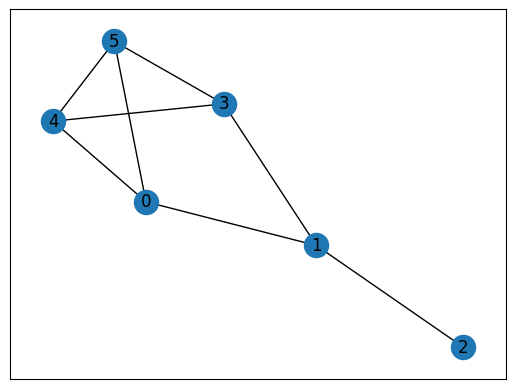

In [57]:
pos = nx.spring_layout(G)

nx.draw_networkx(G, pos=pos)

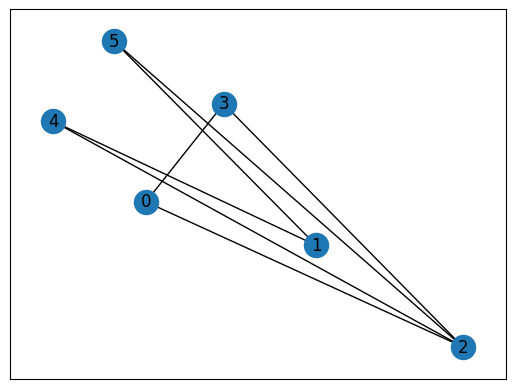

In [58]:
CG = nx.complement(G)
nx.draw_networkx(CG, pos=pos)

In [53]:
def BK(G, R, P0, X, max_cliques):
    if len(P0) == 0 and len(X) == 0:
        max_cliques.append(R)
        return max_cliques
    P = P0.copy()
    for v in P0:
        max_cliques = BK(G, 
                         R.union({v}), 
                         P.intersection(set(G[v])), 
                         X.intersection(set(G[v])), 
                         max_cliques)
        P.remove(v)
        X.add(v)
    return max_cliques    

In [54]:
def Bron_Kerbosch(G):   
    return BK(G, R=set(), P0=set(G.nodes), X=set(), max_cliques=[])

In [66]:
max_cliques = Bron_Kerbosch(CG)
max_cliques

[{0, 2, 3}, {1, 4}, {1, 5}, {2, 4}, {2, 5}]

In [63]:
list(nx.find_cliques(CG))

[[1, 4], [1, 5], [2, 0, 3], [2, 4], [2, 5]]

In [64]:
import pyomo.environ as pyo

In [103]:
import cplex

In [94]:
C = [frozenset(clique) for clique in max_cliques]
C

[frozenset({0, 2, 3}),
 frozenset({1, 4}),
 frozenset({1, 5}),
 frozenset({2, 4}),
 frozenset({2, 5})]

In [100]:
model = pyo.ConcreteModel()
model.C = pyo.Set(initialize=C)
model.V = pyo.Set(initialize=list(G.nodes))

model.x = pyo.Var(model.C, domain=pyo.Binary)
model.obj = pyo.Objective(expr=pyo.summation(model.x)) #min по умолчанию sense

def constraint(m, v):
    return sum(m.x[c] for c in m.C if v in c) >= 1

model.full_constraint = pyo.Constraint(model.V, rule=constraint)

In [115]:
solver = pyo.SolverFactory(
    "cbc",
    executable=r"C:\Users\User\Documents\Solvers\CBC\bin\cbc.exe"
)

print(solver.available())

True


In [119]:
result = solver.solve(model)

In [120]:
result

{'Problem': [{'Name': 'unknown', 'Lower bound': 3.0, 'Upper bound': 3.0, 'Number of objectives': 1, 'Number of constraints': 3, 'Number of variables': 4, 'Number of binary variables': 5, 'Number of integer variables': 5, 'Number of nonzeros': 4, 'Sense': 'minimize'}], 'Solver': [{'Status': 'ok', 'User time': -1.0, 'System time': 0.03, 'Wallclock time': 0.03, 'Termination condition': 'optimal', 'Termination message': 'Model was solved to optimality (subject to tolerances), and an optimal solution is available.', 'Statistics': {'Branch and bound': {'Number of bounded subproblems': 0, 'Number of created subproblems': 0}, 'Black box': {'Number of iterations': 0}}, 'Error rc': 0, 'Time': 0.07986211776733398}], 'Solution': [OrderedDict([('number of solutions', 0), ('number of solutions displayed', 0)])]}

In [130]:
S = [c for c in model.C if pyo.value(model.x[c])]
S

[frozenset({0, 2, 3}), frozenset({1, 5}), frozenset({2, 4})]

In [140]:
colors = {v: i for i in range(len(S)) for v in S[i]}
colors

{0: 0, 2: 2, 3: 0, 1: 1, 5: 1, 4: 2}

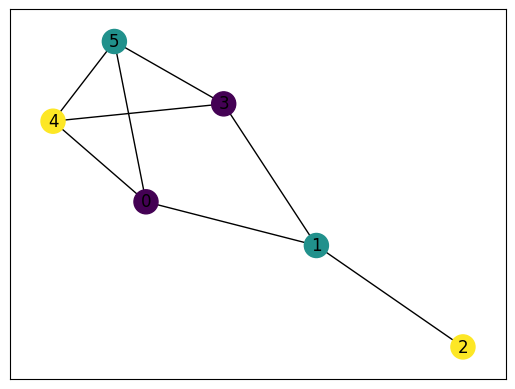

In [141]:
nx.draw_networkx(G, pos=pos, node_color=[colors[v] for v in G.nodes])